# **El Modelo de Regresión Simple (OSL)**

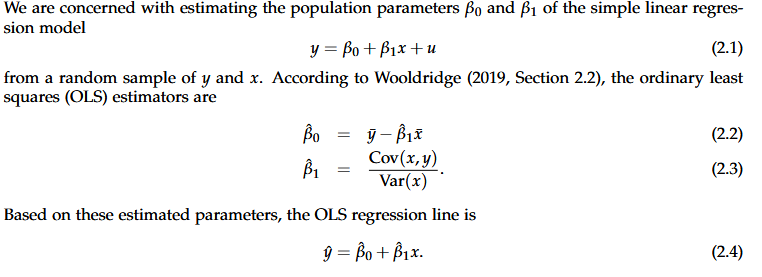

In [ ]:
#Cargar la paquetería de wooldridge
%pip install wooldridge

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 42.1 MB/s eta 0:00:00


In [ ]:
#Caragar o importar las librerías
import wooldridge as woo # Para obtener las bases de datos de Wooldridge
import numpy as np # Para hacer cálculos matemáticos


In [ ]:
# Ahora vamos a cargar el dataset de ceosal1, el cual hace referencia a salarios de CEO
datos = woo.dataWoo('ceosal1')

In [ ]:
#Observando las columnas de la base de datos
datos.head()

,salary,pcsalary,sales,roe,pcroe,ros,indus,finance,consprod,utility,lsalary,lsales
0,1095,20,27595.000000,14.1,106.400002,191,1,0,0,0,6.998509,10.225389
1,1001,32,9958.000000,10.9,-30.600000,13,1,0,0,0,6.908755,9.206132
2,1122,9,6125.899902,23.5,-16.299999,14,1,0,0,0,7.022868,8.720281
3,578,-9,16246.000000,5.9,-25.700001,-21,1,0,0,0,6.359574,9.695602
4,1368,7,21783.199219,13.8,-3.000000,56,1,0,0,0,7.221105,9.988894


In [ ]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   salary    209 non-null    int64  
 1   pcsalary  209 non-null    int64  
 2   sales     209 non-null    float64
 3   roe       209 non-null    float64
 4   pcroe     209 non-null    float64
 5   ros       209 non-null    int64  
 6   indus     209 non-null    int64  
 7   finance   209 non-null    int64  
 8   consprod  209 non-null    int64  
 9   utility   209 non-null    int64  
 10  lsalary   209 non-null    float64
 11  lsales    209 non-null    float64
dtypes: float64(5), int64(7)
memory usage: 19.7 KB


In [ ]:
#Vamos a definir nuestros datos para crear nuestro modelo de regresión lineal
x = datos['roe'] #Rendimiento sobre el capital propio
y = datos['salary'] #Salario del CEO

***Primer opción para generar un modelo de regresión lineal***

In [ ]:
# Definiendo variables para obtener el modelo de OLS
cov_xy = np.cov(x,y)[1,0]
var_x = np.var(x, ddof=1)
x_bar = np.mean(x)
y_bar = np.mean(y)

In [ ]:
#Cálculo manual de los coeficientes del modelo OLS:
b1 = cov_xy/var_x
b0 = y_bar-b1*x_bar

In [ ]:
print(f'b1: {b1}\nb0: {b0}')

b1: 18.50118634521493
b0: 963.1913364725577


La ecuación del modelo de regresión lineal es:

**$y = 18.5x + 963.19$**

In [ ]:
import matplotlib.pyplot as plt


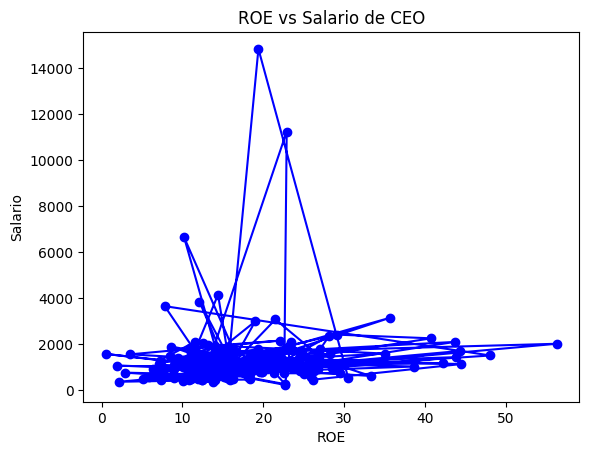

In [ ]:
plt.plot(datos['roe'], datos['salary'], marker='o', color = "blue")
plt.title("ROE vs Salario de CEO")
plt.xlabel("ROE")
plt.ylabel("Salario")
plt.show()


***Segunda opción para generar un modelo de regresión lineal***

In [ ]:
# Importar paquetería para modelo de regresión lineal
import statsmodels.formula.api as smf

In [ ]:
#Crear el modelo de regresión lineal de la forma 'y ~ x'
reg = smf.ols(formula='y ~ x', data = datos)
resultados = reg.fit()

In [ ]:
 #Observemos el modelo de regresión lineal
resultados.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     2.767
Date:                Mon, 21 Sep 2026   Prob (F-statistic):             0.0978
Time:                        22:43:27   Log-Likelihood:                -1804.5
No. Observations:                 209   AIC:                             3613.
Df Residuals:                     207   BIC:                             3620.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    963.1913    213.240      4.517      0.000     542.790    1383.592
x             18.5012     11.123      1.663      0.098      -3.428      40.431
==============================================================================
Omnibus:                      311.096   Durbin-Watson:                   2.105
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            31120.902
Skew:                           6.915   Prob(JB):                         0.00
Kurtosis:                      61.158   Cond. No.                         43.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
R2 = 0.013
R =   np.sqrt(R2)

In [ ]:
print("R =",R)

R = 0.11401754250991379


Se observa a partir del coeficiente de correlación lineal de pearson $(R=0.013)$ y el coeficiente de determinación $(R^2=0.1140)$ que el comportamiento de los datos siendo el $ROE$ a variable independiente y el salario la variable dependiente no es lineal. Por lo cual podemos decir que el $ROE$ no es un buen estimador o pronosticador del salario.